# 03 · Tag queries: the gap in search results

Notebook 02 counted words. Here we look at search results.

Each Google tag gets two queries with the same meaning, one plain and one slang.
The right answers are the places Google tags that way. These are free labels, but noisy.
A throwaway keyword scorer (not our engine) ranks places, and we measure **precision@10**:
how many of the top 10 are right.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from vibecheck.evaluate import TAG_QUERIES, run_queries
from vibecheck.filter_sf import REVIEWS_OUT, load_places
from vibecheck.plots import MUTED, use_style
from vibecheck.report import write_section

use_style()
places = load_places()
reviews = pd.read_parquet(REVIEWS_OUT)

## 1. The queries

To add more, edit `TAG_QUERIES` in `src/vibecheck/evaluate.py`.

In [2]:
pd.DataFrame(TAG_QUERIES)

,misc_key,tag,group,plain,slang
0,Atmosphere,Cozy,cafe,cozy cafe with comfortable seating,comfy lowkey cafe to chill
1,Atmosphere,Romantic,restaurant,romantic restaurant for a date night,restaurant to impress bae
2,Atmosphere,Upscale,restaurant,upscale fancy elegant restaurant,boujee restaurant to flex
3,Atmosphere,Historic,NaN,historic old place with a long history,og old school spot
4,Atmosphere,Trending,NaN,trendy popular new bar,poppin bar everyone is hyped about
5,Popular for,Good for working on laptop,cafe,quiet cafe to work on my laptop with wifi,cafe to grind on homework
6,Crowd,College students,NaN,cheap place popular with college students,spot for broke college kids
7,Crowd,Groups,restaurant,restaurant good for large groups of friends,restaurant for the whole squad


## 2. Score them

*chance* is what picking places at random would score.

In [3]:
results = run_queries(places, reviews)
means = results[["chance", "P@10 plain", "P@10 slang"]].mean()
print(f"mean P@10: plain {means['P@10 plain']:.2f}, slang {means['P@10 slang']:.2f}, chance {means['chance']:.2f}")
results.round(2)

mean P@10: plain 0.48, slang 0.32, chance 0.15


,tag,relevant places,chance,plain query,P@10 plain,slang query,P@10 slang
0,Cozy,371,0.32,cozy cafe with comfortable seating,0.8,comfy lowkey cafe to chill,0.5
1,Romantic,246,0.07,romantic restaurant for a date night,0.9,restaurant to impress bae,0.2
2,Upscale,200,0.05,upscale fancy elegant restaurant,0.3,boujee restaurant to flex,0.3
3,Historic,82,0.01,historic old place with a long history,0.2,og old school spot,0.3
4,Trending,36,0.01,trendy popular new bar,0.0,poppin bar everyone is hyped about,0.0
5,Good for working on laptop,299,0.26,quiet cafe to work on my laptop with wifi,0.5,cafe to grind on homework,0.5
6,College students,711,0.13,cheap place popular with college students,0.4,spot for broke college kids,0.1
7,Groups,1417,0.39,restaurant good for large groups of friends,0.7,restaurant for the whole squad,0.7


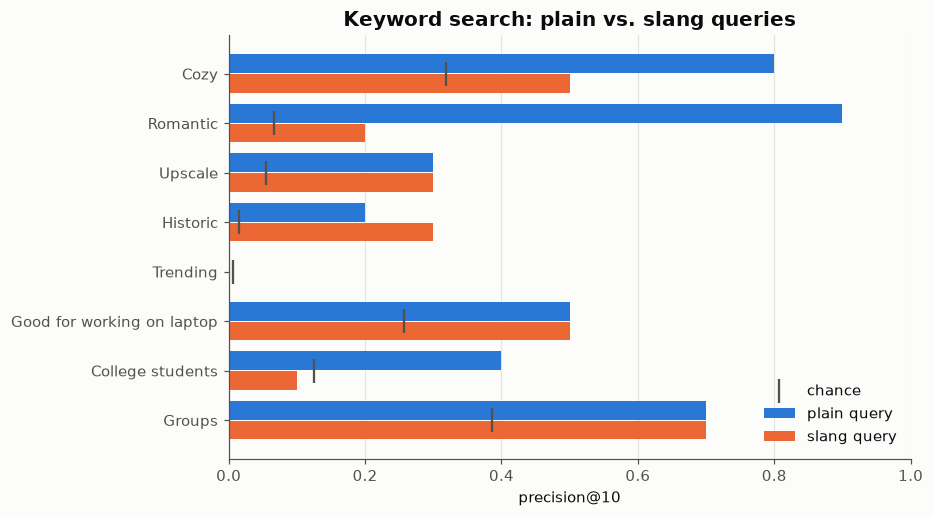

In [4]:
y = np.arange(len(results))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(y - 0.2, results["P@10 plain"], height=0.38, color="#2a78d6", label="plain query")
ax.barh(y + 0.2, results["P@10 slang"], height=0.38, color="#eb6834", label="slang query")
ax.scatter(results["chance"], y, marker="|", s=250, color=MUTED, label="chance", zorder=3)
ax.set_yticks(y, results["tag"])
ax.invert_yaxis()
ax.set(title="Keyword search: plain vs. slang queries", xlabel="precision@10", xlim=(0, 1))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.savefig("../reports/tag_queries.png")
plt.show()

**What this shows**

- Plain queries beat slang ones (0.48 vs. 0.32), and both beat chance (0.15).
- The biggest drops are where the slang word is rare in reviews: "bae" (Romantic 0.9 → 0.2) and
  "broke college kids" (0.4 → 0.1).
- Ties (Groups, laptop) come from a shared plain word ("restaurant", "cafe") doing all the work.
- Trending has only 36 places, too few to score.

This is the bar the real engine has to beat on slang queries.

## 3. Save to `numbers.md`

In [5]:
md = f"""## Tag queries: the gap in search results (notebook 03)

Throwaway keyword scorer, {len(results)} tags, plain vs. slang query with the same meaning.
Labels = places Google tags that way. Mean P@10: **plain {means['P@10 plain']:.2f}, slang {means['P@10 slang']:.2f}**, chance {means['chance']:.2f}.

{results.round(2).to_markdown(index=False)}
"""
write_section("tag_queries", md)
print(md)

## Tag queries: the gap in search results (notebook 03)

Throwaway keyword scorer, 8 tags, plain vs. slang query with the same meaning.
Labels = places Google tags that way. Mean P@10: **plain 0.48, slang 0.32**, chance 0.15.

| tag                        |   relevant places |   chance | plain query                                 |   P@10 plain | slang query                        |   P@10 slang |
|:---------------------------|------------------:|---------:|:--------------------------------------------|-------------:|:-----------------------------------|-------------:|
| Cozy                       |               371 |     0.32 | cozy cafe with comfortable seating          |          0.8 | comfy lowkey cafe to chill         |          0.5 |
| Romantic                   |               246 |     0.07 | romantic restaurant for a date night        |          0.9 | restaurant to impress bae          |          0.2 |
| Upscale                    |               200 |     0.05 | upscale fan